# Polynomial Regression

Here we shall discuss how polynomial regression does better job in identifying true relationship among variables.

## Data

The data is a sample of height, weight, age and gender of peoples of Kung-San tribe in the Kalahari desert of Africa. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("./height_weight_kung_san_people.csv", sep=',')

In [3]:
data.head()

,height,weight,age,male
0,151.765,47.825606,63.0,1
1,139.700,36.485807,63.0,0
2,136.525,31.864838,65.0,0
3,156.845,53.041914,41.0,1
4,145.415,41.276872,51.0,0


In [4]:
data.shape

(544, 4)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 544 entries, 0 to 543
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   height  544 non-null    float64
 1   weight  544 non-null    float64
 2   age     544 non-null    float64
 3   male    544 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 17.1 KB


We shall try to find a relationship between the weight and height of Kung San people using this data.

Here *weight* is our target variable.

## Plotting

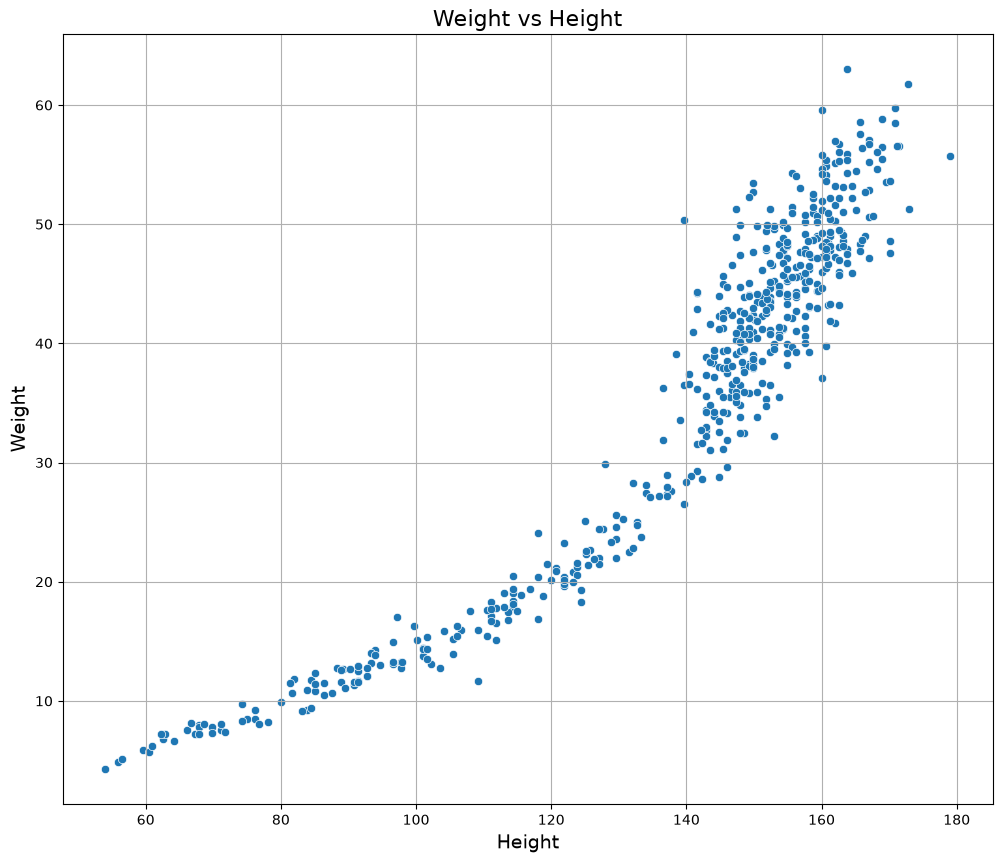

In [6]:
plt.figure(figsize=(12,10))
sns.scatterplot(data=data, x='height', y='weight')
plt.grid()
#plt.legend()
plt.title("Weight vs Height", fontsize=16)
plt.xlabel("Height", fontsize=14)
plt.ylabel("Weight", fontsize=14)
plt.show()

## Polynomial Regression of order 1 (i.e. simple linear regression)

i.e. we are trying fit the equation:

$$ y = \hat{\theta}_0 + \hat{\theta}_1 x $$

Where $x$ is *height* and $y$ is *weight*

In [7]:
from sklearn.linear_model import LinearRegression

### Fit the model

In [8]:
first_order_model = LinearRegression()

In [9]:
first_order_model.fit(X=data['height'].values.reshape(-1,1), y=data['weight'].values)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.5]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-33.76
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[643.2]


### Model parameters

In [10]:
first_order_model.intercept_

np.float64(-33.75613690832986)

In [11]:
first_order_model.coef_

array([0.50169934])

The model looks like:

$$ \hat{weight} = -33.756 + 0.502 \times height$$

### The model output

In [12]:
x_min = data['height'].min()
x_max = data['height'].max()
x_values = np.linspace(x_min, x_max, 100)
y_values_first_order = first_order_model.predict(x_values.reshape(-1,1))

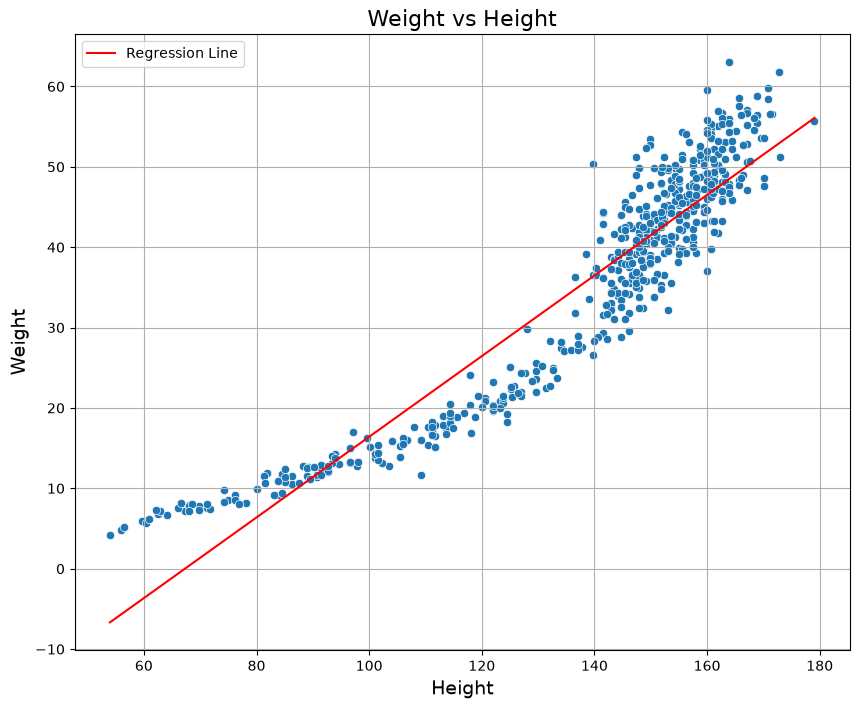

In [13]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=data, x='height', y='weight')
plt.plot(x_values, y_values_first_order, color='r', label='Regression Line')
plt.legend()
plt.grid()
plt.title("Weight vs Height", fontsize=16)
plt.xlabel("Height", fontsize=14)
plt.ylabel("Weight", fontsize=14)
plt.show()

As we can see from the above graph that the "first order regression line" doesn't fit well to the data.
We can use higher order polynomials to describe the relationship.

### Calculate coefficient of determination

In [14]:
from sklearn.metrics import r2_score

In [15]:
y_p_1 = first_order_model.predict(data['height'].values.reshape(-1,1))

In [16]:
error = y_p_1 - data['weight'].values
error

array([-5.44134364e+00, -1.54546136e-01,  2.87352697e+00, -8.10901902e+00,
       -2.07839993e+00, -1.45553237e+01,  2.86647104e+00, -4.49407353e+00,
        5.60290338e+00, -5.41331550e+00, -6.23654083e+00,  8.45510777e-01,
        2.84767849e+00, -6.25140641e+00,  7.89780170e+00, -4.44007232e-01,
        2.92567106e+00,  1.02495108e-01,  7.79319217e+00,  5.18003612e+00,
       -9.18697231e-01, -1.82498697e+00,  1.89161990e+00,  7.64721111e+00,
        5.05034660e+00,  4.19907192e+00,  2.88808596e+00,  4.68898481e+00,
        7.72802605e+00,  6.64292064e+00,  5.72791222e+00,  1.59799384e-01,
       -7.62989989e+00,  2.01066265e+00,  1.01843015e+00, -3.75081811e+00,
       -9.14659244e-01,  2.34553326e+00, -6.92757562e+00, -1.03793555e+00,
       -7.02891564e+00, -1.43180385e+00, -4.29703821e+00,  1.03189931e+00,
       -9.42233162e+00,  1.00768010e+01,  6.99940617e+00,  7.55542803e+00,
        2.03747518e+00,  2.41005667e+00, -3.12585165e-01, -2.55684428e+00,
        6.01012062e-01,  

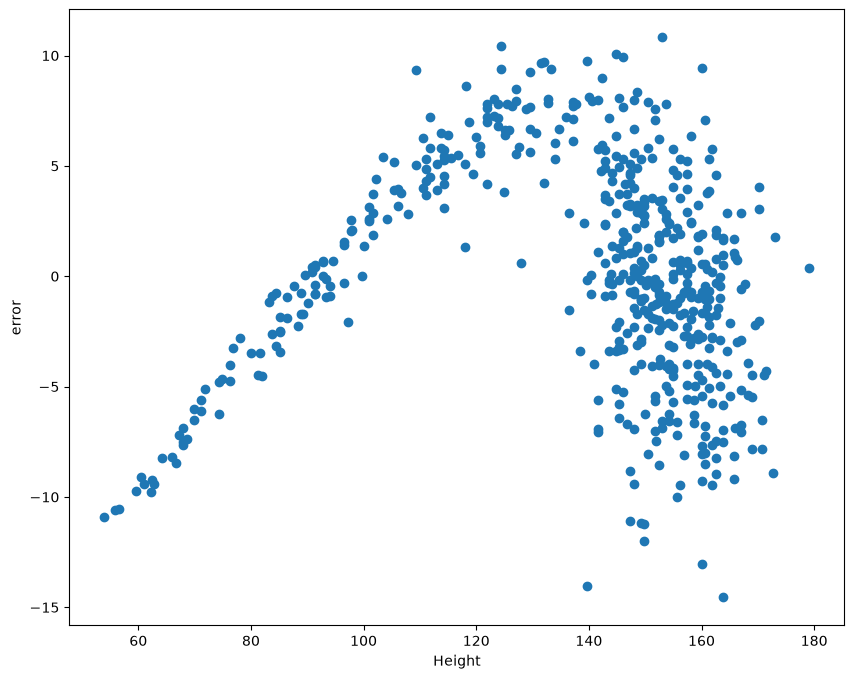

In [17]:
# error vs predictor
plt.figure(figsize=(10,8))
plt.scatter(data['height'].values, error)
plt.xlabel("Height")
plt.ylabel("error")
plt.show()

In [18]:
r2_1 = r2_score(y_true=data['weight'].values, y_pred=y_p_1)

print(f"Coefficient of determination for first order polynomial: {r2_1}")

Coefficient of determination for first order polynomial: 0.8851464200503394


### Calculate adjusted R-squared

In [19]:
def adjusted_R_squared(m, k, r2):
    return (1 - ((m-1)*(1-r2)/(m-k-1)))

In [20]:
m = len(data)
k = 1

In [21]:
adjusted_R_squared(m, k, r2_1)

0.8849345130762625

## Second order Polynomial Regression


i.e. we are trying fit the equation:

$$ y = \hat{\theta}_0 + \hat{\theta}_1 x + \hat{\theta}_2 x^2 $$

Where $x$ is *height* and $y$ is *weight*.

So, in order to achieve that:

- $x_1 = x$

- $x_2 = x^2$

Then the equation becomes

$$ y = \hat{\theta}_0 + \hat{\theta}_1 x_1 + \hat{\theta}_2 x_2 $$

Which can now be solved using Multiple Linear Regression

### Prepare the data

In [22]:
x1 = data['height'].values
x2 = np.square(x1)

$$ X = [x1, x2] $$

In [23]:
X = np.hstack((x1.reshape(-1,1), x2.reshape(-1,1)))

In [24]:
X[:5]

array([[  151.765   , 23032.615225],
       [  139.7     , 19516.09    ],
       [  136.525   , 18639.075625],
       [  156.845   , 24600.354025],
       [  145.415   , 21145.522225]])

In [25]:
pd.DataFrame(X, columns=['height', 'height_square'])

,height,height_square
0,151.765,23032.615225
1,139.700,19516.090000
2,136.525,18639.075625
3,156.845,24600.354025
4,145.415,21145.522225
...,...,...
539,145.415,21145.522225
540,162.560,26425.753600
541,156.210,24401.564100
542,71.120,5058.054400


### Standardization

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
scaler = StandardScaler()

In [28]:
scaler.fit(X=X)

StandardScaler()

In [29]:
X_std = scaler.transform(X)

In [30]:
X_std[:,0].min() , X_std[:,0].max()

(np.float64(-3.05647439422663), np.float64(1.4797224464253014))

In [31]:
X_std[:,1].min() , X_std[:,1].max()

(np.float64(-2.5288189559873486), np.float64(1.8169717368547482))

In [32]:
X_std[:10]

array([[ 0.48958811,  0.47035907],
       [ 0.05208689, -0.05384791],
       [-0.06304501, -0.18458408],
       [ 0.67379915,  0.70406126],
       [ 0.25932431,  0.18905089],
       [ 0.92708933,  1.03796446],
       [ 0.39748259,  0.35639319],
       [ 1.11130037,  1.28993965],
       [ 0.35142983,  0.30013156],
       [ 0.97314209,  1.10023695]])

### fit the model

In [33]:
second_order_model = LinearRegression()

In [34]:
second_order_model.fit(X_std, y=data['weight'].values)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-13.04, 27.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35.61
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[32.93, 1.87]"


### Model parameters

In [35]:
second_order_model.intercept_

np.float64(35.610617592463214)

In [36]:
second_order_model.coef_

array([-13.04264336,  27.05203396])

The model looks like:

$$\hat{weight} = 35.611 + (-13.043) \times height\_std + (27.052) \times height^{2}\_std$$

### Model output

In [37]:
x_min = data['height'].min()
x_max = data['height'].max()
in_between_values = np.linspace(x_min, x_max, 100)

In [38]:
x_values = np.hstack((in_between_values.reshape(-1,1), np.square(in_between_values).reshape(-1,1)))

In [39]:
x_values_std = scaler.transform(x_values)

In [40]:
y_values_second_order = second_order_model.predict(x_values_std)

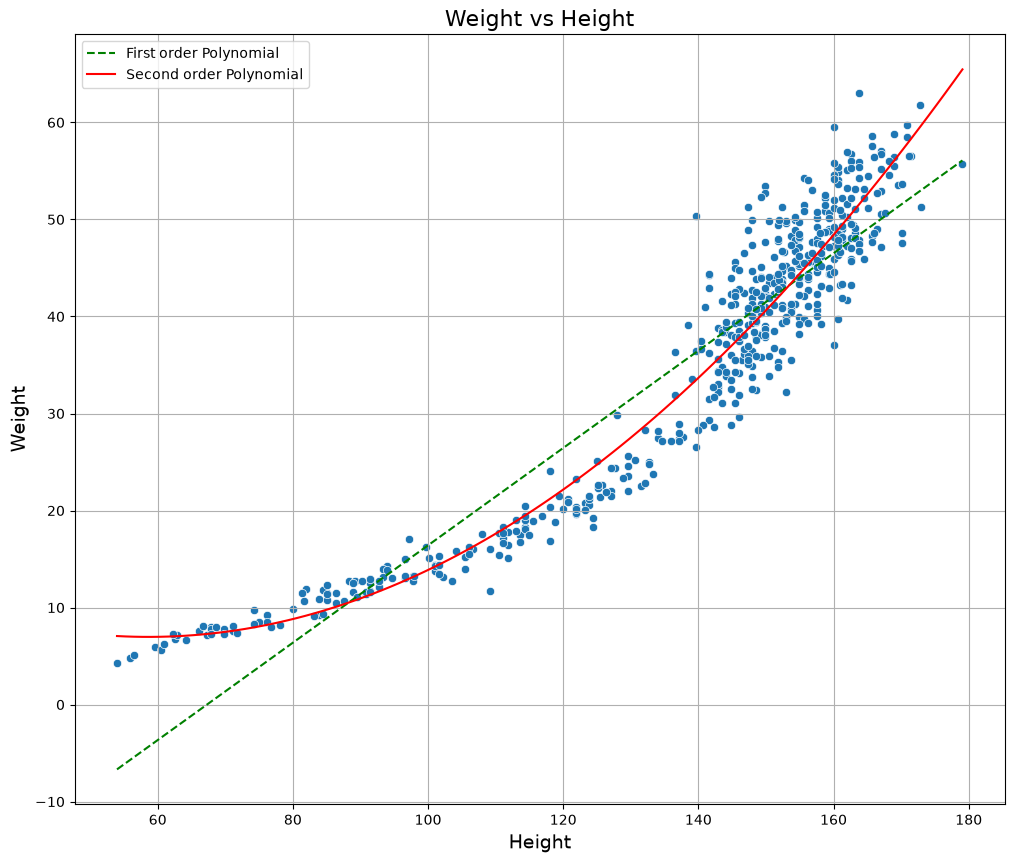

In [41]:
plt.figure(figsize=(12,10))
sns.scatterplot(data=data, x='height', y='weight')
plt.plot(in_between_values, y_values_first_order, 'g--', label='First order Polynomial')
plt.plot(in_between_values, y_values_second_order, color='r', label='Second order Polynomial')
plt.legend()
plt.grid()
plt.title("Weight vs Height", fontsize=16)
plt.xlabel("Height", fontsize=14)
plt.ylabel("Weight", fontsize=14)
plt.show()

### Calculate coefficient of determination

In [42]:
y_p_2 = second_order_model.predict(X_std)

In [43]:
r2_2 = r2_score(y_true=data['weight'].values, y_pred=y_p_2)

print(f"Coefficient of determination for second order polynomial: {r2_2}")

Coefficient of determination for second order polynomial: 0.9285373880898892


In [44]:
adjusted_R_squared(m, k=2, r2=r2_2)

0.928273200984861

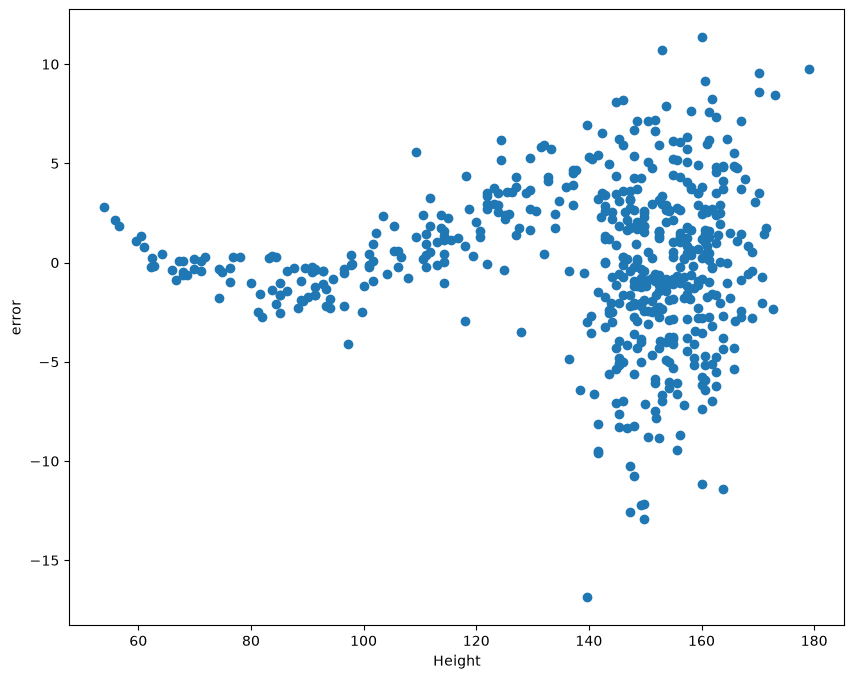

In [45]:
# error vs predictor (residual plot)
plt.figure(figsize=(10,8))
plt.scatter(data['height'].values, y_p_2 - data['weight'].values)
plt.xlabel("Height")
plt.ylabel("error")
plt.show()

## Third order polynomial

i.e. we are trying fit the equation:

$$ y = \hat{\theta}_0 + \hat{\theta}_1 x + \hat{\theta}_2 x^2 + \hat{\theta}_3 x^3 $$

Where $x$ is *height* and $y$ is *weight*.

So, in order to achieve that:

- $x_1 = x$

- $x_2 = x^2$

- $x_3 = x^3$

Then the equation becomes

$$ y = \hat{\theta}_0 + \hat{\theta}_1 x_1 + \hat{\theta}_2 x_2 + \hat{\theta}_3 x_3 $$

Which can now be solved using Multiple Linear Regression

### Prepare the data

In [46]:
x1 = data['height'].values
x2 = np.square(x1)
x3 = np.power(x1, 3)

$$X = [x1, x2, x3] $$

In [47]:
X = np.hstack((x1.reshape(-1,1), x2.reshape(-1,1), x3.reshape(-1,1)))

In [48]:
pd.DataFrame(X, columns=['height', 'height_square', 'height_cube'])

,height,height_square,height_cube
0,151.765,23032.615225,3.495545e+06
1,139.700,19516.090000,2.726398e+06
2,136.525,18639.075625,2.544700e+06
3,156.845,24600.354025,3.858443e+06
4,145.415,21145.522225,3.074876e+06
...,...,...,...
539,145.415,21145.522225,3.074876e+06
540,162.560,26425.753600,4.295771e+06
541,156.210,24401.564100,3.811768e+06
542,71.120,5058.054400,3.597288e+05


### Standardization

In [49]:
scaler = StandardScaler()

In [50]:
scaler.fit(X)

StandardScaler()

In [51]:
X_std = scaler.transform(X)

In [52]:
pd.DataFrame(X_std, columns=['height', 'height_square_std', 'height_cube_std'])

,height,height_square_std,height_cube_std
0,0.489588,0.470359,0.437671
1,0.052087,-0.053848,-0.159800
2,-0.063045,-0.184584,-0.300942
3,0.673799,0.704061,0.719568
4,0.259324,0.189051,0.110897
...,...,...,...
539,0.259324,0.189051,0.110897
540,0.881037,0.976173,1.059283
541,0.650773,0.674428,0.683312
542,-2.434762,-2.209101,-1.998219


### fit the model

In [53]:
third_order_model = LinearRegression()

In [54]:
third_order_model.fit(X_std, y = data['weight'].values)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-25.68, 54.18,-14.64]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35.61
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[40.25, 3.5 , 0.2 ]"


### Model parameters

In [55]:
third_order_model.intercept_

np.float64(35.61061759246321)

In [56]:
third_order_model.coef_

array([-25.68210297,  54.17561278, -14.63828595])

So the model looks like:

$$\hat{weight} = 35.61 + (-25.68) \times height_{std} + (54.18) \times height^2_{std} + (-14.64) \times height^3_{std}$$

### Model output

In [57]:
x_min = data['height'].min()
x_max = data['height'].max()
in_between_values = np.linspace(x_min, x_max, 100)

In [58]:
square_values = np.square(in_between_values)
cube_values = np.power(in_between_values, 3)

In [59]:
x_values = np.hstack((in_between_values.reshape(-1,1), square_values.reshape(-1,1), cube_values.reshape(-1,1)))

In [60]:
x_values_std = scaler.transform(x_values)

In [61]:
y_values_third_order = third_order_model.predict(x_values_std)

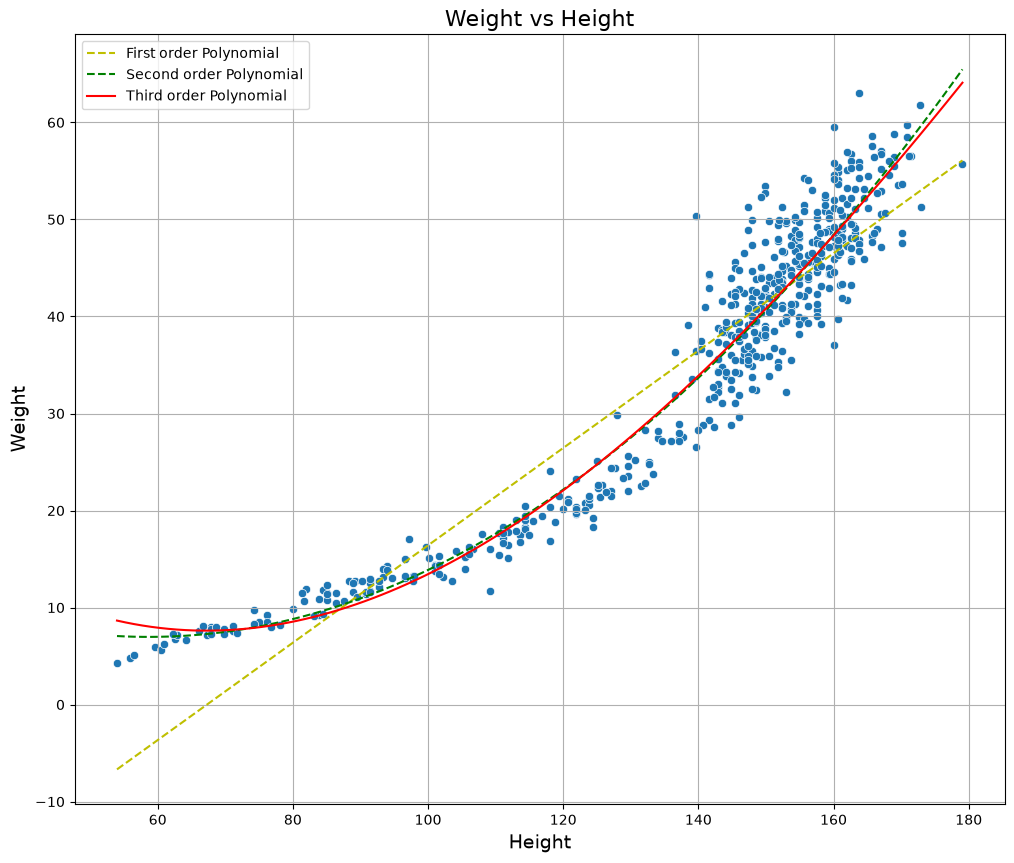

In [62]:
plt.figure(figsize=(12,10))
sns.scatterplot(data=data, x='height', y='weight')
plt.plot(in_between_values, y_values_first_order, 'y--', label='First order Polynomial')
plt.plot(in_between_values, y_values_second_order, 'g--', label='Second order Polynomial')
plt.plot(in_between_values, y_values_third_order, color='r', label='Third order Polynomial')
plt.legend()
plt.grid()
plt.title("Weight vs Height", fontsize=16)
plt.xlabel("Height", fontsize=14)
plt.ylabel("Weight", fontsize=14)
plt.show()

### Calculate coefficient of determination

In [63]:
y_p_3 = third_order_model.predict(X_std)

In [64]:
r2_3 = r2_score(y_true=data['weight'].values, y_pred=y_p_3)

print(f"Coefficient of determination for second order polynomial: {r2_3}")

Coefficient of determination for second order polynomial: 0.9289058038853012


In [65]:
adjusted_R_squared(m, k=3, r2=r2_3)

0.9285108361291085

## Observations

- The first order polynomial doesn't fit the data well.

- The second order polynomial does a good job in terms of fitting the data.

- The third order polynomial is as good as second order polynomial in terms of fiiting the data. 

So we shall restrict ourselves to second order polynomial for this particular dataset.